### Avanziamo solo quando la quarta direzione sigma_4(K_H) > tau

In [1]:
import torch
import torch.nn as nn

# ============================================================
# MODEL
# ============================================================

class MemoryRNN4D(nn.Module):

    def __init__(self, hidden_size=8):
        super().__init__()

        self.hidden_size = hidden_size

        self.Wx = nn.Linear(
            4,
            hidden_size
        )

        self.Wh = nn.Linear(
            hidden_size,
            hidden_size,
            bias=False
        )

        self.readout = nn.Linear(
            hidden_size,
            4
        )

    def forward(self, x):

        batch_size, seq_len, _ = x.shape

        h = torch.zeros(
            batch_size,
            self.hidden_size,
            device=x.device
        )

        states = []

        for t in range(seq_len):

            h = torch.tanh(
                self.Wx(x[:, t])
                + self.Wh(h)
            )

            states.append(h)

        y_hat = self.readout(h)

        return y_hat, states


# ============================================================
# DATASET
# ============================================================

def generate_batch_4d(
    batch_size=128,
    seq_len=7
):

    x = torch.zeros(
        batch_size,
        seq_len,
        4
    )

    values = torch.randint(
        1,
        10,
        (batch_size, 4)
    ).float() / 9.0

    # Tutta la memoria entra simultaneamente a t=0
    x[:, 0, :] = values

    y = values.clone()

    return x, y

In [2]:
torch.manual_seed(42)

model4 = MemoryRNN4D(
    hidden_size=8
)

optimizer4 = torch.optim.Adam(
    model4.parameters(),
    lr=0.003
)

criterion = nn.MSELoss()


for epoch in range(4000):

    x_batch, y_batch = generate_batch_4d(
        batch_size=128,
        seq_len=7
    )

    optimizer4.zero_grad()

    pred, _ = model4(x_batch)

    # Solo output finale
    loss = criterion(
        pred,
        y_batch
    )

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model4.parameters(),
        1.0
    )

    optimizer4.step()

    if epoch % 500 == 0:
        print(
            f"BASE | epoch={epoch} | "
            f"loss={loss.item():.7f}"
        )

BASE | epoch=0 | loss=0.7278466
BASE | epoch=500 | loss=0.0413444
BASE | epoch=1000 | loss=0.0376567
BASE | epoch=1500 | loss=0.0379789
BASE | epoch=2000 | loss=0.0398384
BASE | epoch=2500 | loss=0.0238047
BASE | epoch=3000 | loss=0.0190210
BASE | epoch=3500 | loss=0.0184170


In [3]:
def persistent_loss(model, values, T):
    x = torch.zeros(1, T, 4)
    x[0, 0] = values
    pred, states = model(x)

    loss = 0.0

    for h_t in states:
        y_t = model.readout(h_t)
        loss = loss + ((y_t.squeeze(0) - values) ** 2).mean()

    return loss / len(states)

In [4]:
torch.manual_seed(42)

model4_persistent = MemoryRNN4D(
    hidden_size=8
)

optimizer4_persistent = torch.optim.Adam(
    model4_persistent.parameters(),
    lr=0.003
)


for epoch in range(4000):

    x_batch, y_batch = generate_batch_4d(
        batch_size=128,
        seq_len=7
    )

    optimizer4_persistent.zero_grad()

    _, states = model4_persistent(
        x_batch
    )

    loss = 0.0

    for h_t in states:

        y_t = model4_persistent.readout(
            h_t
        )

        loss = loss + criterion(
            y_t,
            y_batch
        )

    loss = loss / len(states)

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model4_persistent.parameters(),
        1.0
    )

    optimizer4_persistent.step()

    if epoch % 500 == 0:
        print(
            f"PERSISTENT | epoch={epoch} | "
            f"loss={loss.item():.7f}"
        )

PERSISTENT | epoch=0 | loss=0.7100286
PERSISTENT | epoch=500 | loss=0.0362196
PERSISTENT | epoch=1000 | loss=0.0020995
PERSISTENT | epoch=1500 | loss=0.0011145
PERSISTENT | epoch=2000 | loss=0.0006351
PERSISTENT | epoch=2500 | loss=0.0003621
PERSISTENT | epoch=3000 | loss=0.0003246
PERSISTENT | epoch=3500 | loss=0.0001990


In [5]:
def jacobian_at_horizon(
    model,
    values,
    H,
    create_graph=True
):

    z = (
        values
        .detach()
        .clone()
        .requires_grad_(True)
    )

    def f(z_local):

        first = z_local.reshape(
            1, 1, 4
        )

        if H > 1:

            rest = torch.zeros(
                1,
                H - 1,
                4
            )

            x = torch.cat(
                [first, rest],
                dim=1
            )

        else:

            x = first

        pred, _ = model(x)

        return pred.squeeze(0)

    K = torch.autograd.functional.jacobian(
        f,
        z,
        create_graph=create_graph
    )

    return K

In [6]:
def evaluate_model_4d(
    model,
    seq_len,
    n_batches=100,
    batch_size=256
):

    errors = []

    model.eval()

    with torch.no_grad():

        for _ in range(n_batches):

            x, y = generate_batch_4d(
                batch_size=batch_size,
                seq_len=seq_len
            )

            pred, _ = model(x)

            error = (
                torch.abs(pred - y)
                * 9.0
            )

            errors.append(error)

    errors = torch.cat(errors)

    per_dim = errors.mean(dim=0)

    return (
        per_dim.tolist(),
        errors.mean().item()
    )

In [7]:
# Sanity check

print("T | baseline | persistent")

for T in [7, 8, 16, 32, 64]:

    _, base = evaluate_model_4d(
        model4,
        T
    )

    _, pers = evaluate_model_4d(
        model4_persistent,
        T
    )

    print(
        f"{T:2d} | "
        f"{base:.4f} | "
        f"{pers:.4f}"
    )

T | baseline | persistent
 7 | 0.1681 | 0.1361
 8 | 3.8442 | 0.1557
16 | 6.2482 | 0.3135
32 | 5.2182 | 0.6133
64 | 7.4328 | 1.1580


In [8]:
# NUOVO MODELLO

torch.manual_seed(42)

model4_curr = MemoryRNN4D(
    hidden_size=8
)

optimizer4_curr = torch.optim.Adam(
    model4_curr.parameters(),
    lr=0.001
)

lambda_jac = 0.1

In [9]:
def persistent_loss(
    model,
    values,
    T
):

    x = torch.zeros(
        1, T, 4
    )

    x[0, 0] = values

    pred, states = model(x)

    loss = 0.0

    for h_t in states:

        y_t = model.readout(h_t)

        loss = loss + (
            (y_t.squeeze(0) - values) ** 2
        ).mean()

    return loss / len(states)


In [10]:
def jacobian_at_horizon(
    model,
    values,
    H,
    create_graph=True
):

    z = (
        values
        .detach()
        .clone()
        .requires_grad_(True)
    )

    def f(z_local):

        first = z_local.reshape(
            1, 1, 4
        )

        if H > 1:

            rest = torch.zeros(
                1,
                H - 1,
                4
            )

            x = torch.cat(
                [first, rest],
                dim=1
            )

        else:

            x = first

        pred, _ = model(x)

        return pred.squeeze(0)

    K = torch.autograd.functional.jacobian(
        f,
        z,
        create_graph=create_graph
    )

    return K

In [11]:
STAGES = [2, 4, 8, 16, 32]

def curriculum_jacobian_loss(
    model,
    values,
    current_H
):

    active_H = [
        H for H in STAGES
        if H <= current_H
    ]

    losses = []

    for H in active_H:

        K = jacobian_at_horizon(
            model,
            values,
            H,
            create_graph=True
        )

        I = torch.eye(
            4,
            device=K.device,
            dtype=K.dtype
        )

        L_H = torch.sum(
            (K - I) ** 2
        ) / 4.0

        losses.append(L_H)

    return torch.stack(losses).mean()

In [12]:
probe_values = torch.tensor([
    [7., 3., 5., 2.],
    [2., 8., 4., 6.],
    [9., 1., 7., 3.],
    [4., 6., 2., 8.],
]) / 9.0

In [13]:
def mean_sigma4(model, H):
    sigma4_values = []

    for values in probe_values:
        K = jacobian_at_horizon(model, values, H, create_graph=False)

        S = torch.linalg.svdvals(K.detach())

        sigma4_values.append(S[-1].item())

    return(sum(sigma4_values) / len(sigma4_values))

In [14]:
# Due controlli consecutivi sopra soglia, per evitare una singola fluttuazione possa far avanzare stage

threshold = 0.15

check_every = 100
required_successes = 2

stage_index = 0
current_H = STAGES[stage_index]

success_count = 0

max_steps = 12000

log_file = "jacobian_curriculum_log2.txt"

with open(log_file, "w") as f:
    f.write(
        "JACOBIAN-DRIVEN TEMPORAL CURRICULUM\n"
    )
    f.write("=" * 70 + "\n")


In [15]:
for step in range(max_steps):

    # -----------------------------
    # Random memory
    # -----------------------------

    values = (
        torch.randint(
            1, 10, (4,)
        ).float()
        / 9.0
    )


    # -----------------------------
    # Loss
    # -----------------------------

    optimizer4_curr.zero_grad()

    value_loss = persistent_loss(
        model4_curr,
        values,
        current_H
    )

    jac_loss = curriculum_jacobian_loss(
        model4_curr,
        values,
        current_H
    )

    loss = (
        value_loss
        + lambda_jac * jac_loss
    )


    # -----------------------------
    # Backprop
    # -----------------------------

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model4_curr.parameters(),
        1.0
    )

    optimizer4_curr.step()


    # -----------------------------
    # Curriculum check
    # -----------------------------

    if step % check_every == 0:

        sigma4 = mean_sigma4(
            model4_curr,
            current_H
        )

        with open(log_file, "a") as f:

            f.write(
                f"\nstep={step}\n"
            )

            f.write(
                f"stage_H={current_H}\n"
            )

            f.write(
                f"value_loss="
                f"{value_loss.item():.8f}\n"
            )

            f.write(
                f"jac_loss="
                f"{jac_loss.item():.8f}\n"
            )

            f.write(
                f"sigma4="
                f"{sigma4:.8f}\n"
            )

        print(
            f"step={step:5d} | "
            f"H={current_H:2d} | "
            f"value={value_loss.item():.5f} | "
            f"jac={jac_loss.item():.5f} | "
            f"sigma4={sigma4:.5f}"
        )


        # -----------------------------
        # Mastery decision
        # -----------------------------

        if sigma4 >= threshold:

            success_count += 1

        else:

            success_count = 0


        # Due check consecutivi sopra soglia
        if (
            success_count
            >= required_successes
        ):

            if stage_index < len(STAGES) - 1:

                old_H = current_H

                stage_index += 1

                current_H = STAGES[
                    stage_index
                ]

                success_count = 0

                print(
                    "\n"
                    "=============================="
                )

                print(
                    f"MASTERED H={old_H}"
                )

                print(
                    f"ADVANCING TO H={current_H}"
                )

                print(
                    "==============================\n"
                )

                with open(
                    log_file,
                    "a"
                ) as f:

                    f.write(
                        f"\nMASTERED H={old_H}"
                        f" -> H={current_H}\n"
                    )

            else:

                print(
                    "\nMAXIMUM HORIZON MASTERED\n"
                )

step=    0 | H= 2 | value=0.69418 | jac=0.99459 | sigma4=0.00216
step=  100 | H= 2 | value=0.24803 | jac=0.84543 | sigma4=0.00065
step=  200 | H= 2 | value=0.15097 | jac=0.75933 | sigma4=0.00711
step=  300 | H= 2 | value=0.05154 | jac=0.67109 | sigma4=0.00714
step=  400 | H= 2 | value=0.02224 | jac=0.62486 | sigma4=0.02829
step=  500 | H= 2 | value=0.05246 | jac=0.50249 | sigma4=0.06089
step=  600 | H= 2 | value=0.05680 | jac=0.43872 | sigma4=0.10774
step=  700 | H= 2 | value=0.06069 | jac=0.28599 | sigma4=0.18077
step=  800 | H= 2 | value=0.01533 | jac=0.23313 | sigma4=0.27203

MASTERED H=2
ADVANCING TO H=4

step=  900 | H= 4 | value=0.04131 | jac=0.25453 | sigma4=0.01178
step= 1000 | H= 4 | value=0.02643 | jac=0.20786 | sigma4=0.01891
step= 1100 | H= 4 | value=0.01344 | jac=0.23425 | sigma4=0.07929
step= 1200 | H= 4 | value=0.01525 | jac=0.22829 | sigma4=0.17075
step= 1300 | H= 4 | value=0.09421 | jac=0.19477 | sigma4=0.33581

MASTERED H=4
ADVANCING TO H=8

step= 1400 | H= 8 | value=

In [31]:
print(
    "T | final-only | persistent | curriculum"
)

for T in [
    7, 8, 12, 16,
    24, 32, 64, 128
]:

    _, base = evaluate_model_4d(
        model4,
        T
    )

    _, pers = evaluate_model_4d(
        model4_persistent,
        T
    )

    _, curr = evaluate_model_4d(
        model4_curr,
        T
    )

    print(f"{T:3d} | "
        f"{base:.5f} | "
        f"{pers:.5f} | "
        f"{curr:.5f}")

T | final-only | persistent | curriculum
  7 | 0.16789 | 0.13613 | 1.28104
  8 | 3.86206 | 0.15661 | 0.44623
 12 | 2.90253 | 0.23413 | 0.53702
 16 | 6.24608 | 0.31168 | 0.57780
 24 | 6.43209 | 0.46614 | 0.63886
 32 | 5.21865 | 0.61433 | 0.70590
 64 | 7.41957 | 1.15252 | 1.05139
128 | 5.13409 | 1.95229 | 1.76498


In [32]:
steps_log = []
H_log = []
sigma_log = []

with open(
    "jacobian_curriculum_log2.txt"
) as f:

    lines = f.readlines()

for i, line in enumerate(lines):

    if line.startswith("step="):

        step = int(
            line.split("=")[1]
        )

        H = int(
            lines[i+1]
            .split("=")[1]
        )

        sigma = float(
            lines[i+4]
            .split("=")[1]
        )

        steps_log.append(step)
        H_log.append(H)
        sigma_log.append(sigma)

In [33]:
def evaluate_model_4d(model, seq_len, n_batches=100, batch_size=256):
    errors = []
    model.eval()

    with torch.no_grad():
        for _ in range(n_batches):
            x, y = generate_batch_4d(batch_size=batch_size, seq_len=seq_len)

            pred, _ = model(x)
            error = torch.abs(pred - y) * 9.0
            errors.append(error)

    errors = torch.cat(errors)

    return(errors.mean(dim=0).tolist(), errors.mean().item())

In [34]:
torch.save(
    model4.state_dict(),
    "model4_baseline.pt"
)

torch.save(
    model4_persistent.state_dict(),
    "model4_persistent.pt"
)

torch.save(
    model4_curr.state_dict(),
    "model4_curriculum.pt"
)

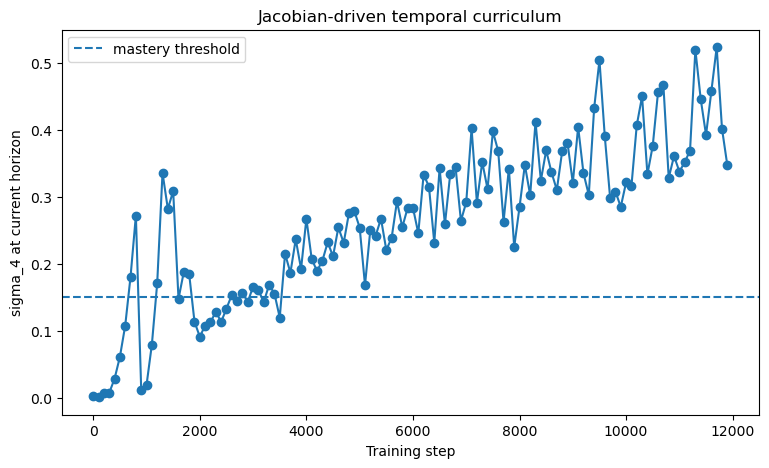

In [35]:
# Grafico
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    steps_log,
    sigma_log,
    marker="o"
)

plt.axhline(
    threshold,
    linestyle="--",
    label="mastery threshold"
)

plt.xlabel(
    "Training step"
)

plt.ylabel(
    "sigma_4 at current horizon"
)

plt.title(
    "Jacobian-driven temporal curriculum"
)

plt.legend()
plt.show()

In [36]:
torch.save(
    model4_curr.state_dict(),
    "model4_curriculum_final.pt"
)

## A) Curriculum marcato da sigma_4
## B) H = 32 fino dall'inizio
## C) Orizzonti casuali

In [37]:
import copy
import torch

torch.manual_seed(12345)

initial_model = MemoryRNN4D(
    hidden_size=8
)

initial_state = copy.deepcopy(
    initial_model.state_dict()
)

In [38]:
def make_identical_model():

    model = MemoryRNN4D(
        hidden_size=8
    )

    model.load_state_dict(
        copy.deepcopy(initial_state)
    )

    return model

In [39]:
BUDGET = 6000

g_values = torch.Generator()
g_values.manual_seed(2026)

training_values = (
    torch.randint(
        1,
        10,
        (BUDGET, 4),
        generator=g_values
    ).float()
    / 9.0
)

In [40]:

STAGES = [2, 4, 8, 16, 32]

def jacobian_loss_for_horizons(
    model,
    values,
    horizons
):

    losses = []

    for H in horizons:

        K = jacobian_at_horizon(
            model,
            values,
            H,
            create_graph=True
        )

        I = torch.eye(
            4,
            device=K.device,
            dtype=K.dtype
        )

        L_H = (
            torch.sum(
                (K - I) ** 2
            )
            / 4.0
        )

        losses.append(L_H)

    return torch.stack(
        losses
    ).mean()

In [41]:
# A) Curriculum

def train_curriculum(
    budget,
    training_values,
    threshold=0.15,
    lambda_jac=0.1,
    lr=0.001
):

    model = make_identical_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    stage_index = 0
    current_H = STAGES[stage_index]

    success_count = 0
    required_successes = 2

    log = []

    for step in range(budget):

        values = training_values[step]

        optimizer.zero_grad()

        value_loss = persistent_loss(
            model,
            values,
            current_H
        )

        active = [
            H for H in STAGES
            if H <= current_H
        ]

        jac_loss = jacobian_loss_for_horizons(
            model,
            values,
            active
        )

        loss = (
            value_loss
            + lambda_jac * jac_loss
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()


        # controllo curriculum
        if step % 100 == 0:

            sigma4 = mean_sigma4(
                model,
                current_H
            )

            log.append({
                "step": step,
                "H": current_H,
                "value": value_loss.item(),
                "jac": jac_loss.item(),
                "sigma4": sigma4
            })

            if sigma4 >= threshold:
                success_count += 1
            else:
                success_count = 0

            if (
                success_count >= required_successes
                and
                stage_index < len(STAGES)-1
            ):

                stage_index += 1
                current_H = STAGES[
                    stage_index
                ]

                success_count = 0

                print(
                    f"A curriculum -> H={current_H}"
                )

    return model, log

In [42]:
# B) H = 32

def train_direct32(
    budget,
    training_values,
    lambda_jac=0.1,
    lr=0.001
):

    model = make_identical_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    log = []

    for step in range(budget):

        values = training_values[step]

        optimizer.zero_grad()

        value_loss = persistent_loss(
            model,
            values,
            32
        )

        jac_loss = jacobian_loss_for_horizons(
            model,
            values,
            STAGES
        )

        loss = (
            value_loss
            + lambda_jac * jac_loss
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()

        if step % 100 == 0:

            sigma4 = mean_sigma4(
                model,
                32
            )

            log.append({
                "step": step,
                "H": 32,
                "value": value_loss.item(),
                "jac": jac_loss.item(),
                "sigma4": sigma4
            })

    return model, log

In [43]:
# C) Orizzonte casuale

g_H = torch.Generator()
g_H.manual_seed(999)

random_indices = torch.randint(
    0,
    len(STAGES),
    (BUDGET,),
    generator=g_H
)

random_H_schedule = [
    STAGES[i]
    for i in random_indices.tolist()
]

In [44]:
def train_random_horizon(
    budget,
    training_values,
    H_schedule,
    lambda_jac=0.1,
    lr=0.001
):

    model = make_identical_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    log = []

    for step in range(budget):

        values = training_values[step]

        current_H = H_schedule[step]

        optimizer.zero_grad()

        value_loss = persistent_loss(
            model,
            values,
            current_H
        )

        active = [
            H for H in STAGES
            if H <= current_H
        ]

        jac_loss = jacobian_loss_for_horizons(
            model,
            values,
            active
        )

        loss = (
            value_loss
            + lambda_jac * jac_loss
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()

        if step % 100 == 0:

            # SEMPRE valutiamo H=32,
            # indipendentemente dal training H
            sigma4_32 = mean_sigma4(
                model,
                32
            )

            log.append({
                "step": step,
                "H": current_H,
                "value": value_loss.item(),
                "jac": jac_loss.item(),
                "sigma4": sigma4_32
            })

    return model, log

In [ ]:
model_A, log_A = train_curriculum(
    BUDGET,
    training_values
)

torch.save(
    model_A.state_dict(),
    "model_A_curriculum.pt"
)

A curriculum -> H=4
A curriculum -> H=8
A curriculum -> H=16
A curriculum -> H=32


In [50]:
model_B, log_B = train_direct32(
    BUDGET,
    training_values
)

torch.save(
    model_B.state_dict(),
    "model_B_direct32.pt"
)

In [51]:
model_C, log_C = train_random_horizon(
    BUDGET,
    training_values,
    random_H_schedule
)

torch.save(
    model_C.state_dict(),
    "model_C_random.pt"
)

In [52]:
# Primo test: performance reale

print(
    "T | Curriculum | Direct32 | Random"
)

for T in [
    7, 16, 32,
    64, 128
]:

    _, A = evaluate_model_4d(
        model_A,
        T
    )

    _, B = evaluate_model_4d(
        model_B,
        T
    )

    _, C = evaluate_model_4d(
        model_C,
        T
    )

    print(
        f"{T:3d} | "
        f"{A:.5f} | "
        f"{B:.5f} | "
        f"{C:.5f}"
    )

T | Curriculum | Direct32 | Random
  7 | 1.57668 | 2.34703 | 0.50988
 16 | 0.62585 | 0.93831 | 0.89541
 32 | 0.76277 | 1.18142 | 1.58704
 64 | 1.24668 | 1.53480 | 3.36255
128 | 2.61652 | 2.03238 | 8.14157


In [53]:
probe = torch.tensor(
    [7., 3., 5., 2.]
) / 9.0

In [54]:
def spectrum_at_T(
    model,
    T,
    values=probe
):

    K = jacobian_at_horizon(
        model,
        values,
        T,
        create_graph=False
    )

    S = torch.linalg.svdvals(
        K.detach()
    )

    return S.cpu().numpy()

In [55]:
for T in [
    7, 16, 32,
    64, 128
]:

    print(f"\nT={T}")

    print(
        "A curriculum:",
        spectrum_at_T(
            model_A,
            T
        )
    )

    print(
        "B direct32:",
        spectrum_at_T(
            model_B,
            T
        )
    )

    print(
        "C random:",
        spectrum_at_T(
            model_C,
            T
        )
    )


T=7
A curriculum: [0.9593046  0.9092707  0.7907686  0.52493745]
B direct32: [1.0054336 0.8114818 0.5835437 0.446128 ]
C random: [1.1888063  0.93880886 0.821592   0.73760134]

T=16
A curriculum: [0.99836993 0.8572732  0.78942007 0.44987637]
B direct32: [1.0383192  0.68365437 0.5650386  0.2891311 ]
C random: [1.3484975  0.94339037 0.79666644 0.6411974 ]

T=32
A curriculum: [1.0364624  0.8472838  0.69813526 0.33057925]
B direct32: [1.1248894  0.5427116  0.47292122 0.16355933]
C random: [1.6902488  1.0111543  0.58040386 0.3747694 ]

T=64
A curriculum: [1.176708   0.80420977 0.51730657 0.17785999]
B direct32: [1.472684   0.41403276 0.26375982 0.0693751 ]
C random: [2.75903    1.5407277  0.2961869  0.10720327]

T=128
A curriculum: [1.6543915  0.5826214  0.2476954  0.04885758]
B direct32: [2.9014142  0.21216515 0.06894135 0.01676096]
C random: [7.2612519e+00 3.3303437e-01 9.5824013e-03 1.8873797e-03]
